# Thực nghiệm PhoBERT – viBERT – XLM-R trên UIT-VSFC

**Mục tiêu:** phân loại cảm xúc phản hồi sinh viên bằng 3 mô hình PLM, fine-tune và so sánh trên cùng test set.

## Trước khi chạy
1. Mở Google Colab: https://colab.research.google.com/
2. Upload notebook này.
3. Chọn **Runtime → Change runtime type → T4 GPU** (nếu có).
4. Nếu giảng viên cung cấp bộ UIT-VSFC hoặc đường dẫn tải chính thức, dùng đúng dữ liệu đó. Notebook hỗ trợ hai cách: tải file ZIP từ URL được phép chia sẻ, hoặc upload file ZIP/CSV thủ công.
5. Không đưa dữ liệu cá nhân/nhạy cảm lên môi trường công khai.

**Lưu ý học thuật:** UIT-VSFC có thể được phân phối theo nhiều cấu trúc thư mục/phiên bản. Không nên tự đoán tên cột hoặc thứ tự nhãn. Cell khám phá dữ liệu bên dưới sẽ in cấu trúc để kiểm tra trước khi huấn luyện.


## 1. Cài thư viện

In [ ]:
!pip -q install -U transformers accelerate sentencepiece underthesea scikit-learn pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.


In [ ]:
import os, re, glob, zipfile, random, time, gc, json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from underthesea import word_tokenize
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments, DataCollatorWithPadding, set_seed

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Thiết bị:", DEVICE)
if DEVICE == "cuda": print(torch.cuda.get_device_name(0))


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Thiết bị: cuda
Tesla T4


## 2. Tải UIT-VSFC trực tiếp trong Colab

Trang UIT NLP Group giới thiệu UIT-VSFC version 1.0 và liên kết tải Google Drive. Một bản mô tả bộ dữ liệu công khai bởi SEACrowd liệt kê rõ các file `sentences`, `sentiments`, `topics` tách riêng theo ba split `train`, `validation`, `test`. Notebook tải các file câu và nhãn cảm xúc, giữ nguyên split gốc.

**Lưu ý giấy phép:** bản ghi SEACrowd ghi license là unknown. Nếu dùng cho báo cáo/mục đích học thuật, hãy tuân thủ điều khoản corpus và hướng dẫn của nhóm UIT; không phân phối lại dữ liệu. Nếu link tải bị giới hạn, tải từ trang UIT NLP Group hoặc liên hệ nhóm tác giả để xin quyền truy cập.

In [ ]:
!pip -q install gdown

import os, gdown
from pathlib import Path

# Google Drive file IDs được liệt kê trong loader SEACrowd của UIT-VSFC.
# Mỗi split có 2 file cần cho sentiment: sentences và sentiments.
FILE_IDS = {
    "train_sentences": "1nzak5OkrheRV1ltOGCXkT671bmjODLhP",
    "train_sentiments": "1ye-gOZIBqXdKOoi_YxvpT6FeRNmViPPv",
    "validation_sentences": "1sMJSR3oRfPc3fe1gK-V3W5F24tov_517",
    "validation_sentiments": "1GiY1AOp41dLXIIkgES4422AuDwmbUseL",
    "test_sentences": "1aNMOeZZbNwSRkjyCWAGtNCMa3YrshR-n",
    "test_sentiments": "1vkQS5gI0is4ACU58-AbWusnemw7KZNfO",
}

os.makedirs("/content/uit_vsfc", exist_ok=True)
for name, file_id in FILE_IDS.items():
    out = f"/content/uit_vsfc/{name}.txt"
    if not os.path.exists(out):
        url = f"https://drive.google.com/uc?id={file_id}&export=download"
        print("Đang tải", name)
        gdown.download(url, out, quiet=False)
    if not os.path.exists(out) or os.path.getsize(out) == 0:
        raise RuntimeError(f"Không tải được {name}. Hãy tải thủ công từ trang UIT NLP Group.")

def read_lines(name):
    with open(f"/content/uit_vsfc/{name}.txt", encoding="utf-8") as f:
        return [line.strip() for line in f]

train_texts = read_lines("train_sentences")
train_labels = [int(x) for x in read_lines("train_sentiments")]
val_texts = read_lines("validation_sentences")
val_labels = [int(x) for x in read_lines("validation_sentiments")]
test_texts = read_lines("test_sentences")
test_labels = [int(x) for x in read_lines("test_sentiments")]

for split_name, texts, labels in [
    ("train", train_texts, train_labels),
    ("validation", val_texts, val_labels),
    ("test", test_texts, test_labels)
]:
    assert len(texts) == len(labels), f"Số câu và nhãn lệch ở {split_name}"
    print(split_name, "số mẫu:", len(texts), "nhãn:", sorted(set(labels)))

# Nhãn theo ClassLabel trong loader dataset: 0=positive, 1=negative, 2=neutral.
# Đổi sang thứ tự dễ đọc thống nhất: 0=negative, 1=neutral, 2=positive.
RAW_TO_CANONICAL = {0: 2, 1: 0, 2: 1}
def make_frame(texts, labels):
    return pd.DataFrame({
        "text": texts,
        "label": [RAW_TO_CANONICAL[x] for x in labels]
    })

train_df = make_frame(train_texts, train_labels)
val_df = make_frame(val_texts, val_labels)
test_df = make_frame(test_texts, test_labels)

LABEL_NAMES = {0: "negative", 1: "neutral", 2: "positive"}
classes = [0, 1, 2]
id2label = LABEL_NAMES
print("\\nPhân bố nhãn (0=negative, 1=neutral, 2=positive):")
for name, part in [("train",train_df),("validation",val_df),("test",test_df)]:
    print(name, part["label"].value_counts().sort_index().to_dict())
display(train_df.head())


Đang tải train_sentences


Downloading...
From: https://drive.google.com/uc?id=1nzak5OkrheRV1ltOGCXkT671bmjODLhP&export=download
To: /content/uit_vsfc/train_sentences.txt
100%|██████████| 898k/898k [00:00<00:00, 9.95MB/s]


Đang tải train_sentiments


Downloading...
From: https://drive.google.com/uc?id=1ye-gOZIBqXdKOoi_YxvpT6FeRNmViPPv&export=download
To: /content/uit_vsfc/train_sentiments.txt
100%|██████████| 22.9k/22.9k [00:00<00:00, 23.0MB/s]


Đang tải validation_sentences


Downloading...
From: https://drive.google.com/uc?id=1sMJSR3oRfPc3fe1gK-V3W5F24tov_517&export=download
To: /content/uit_vsfc/validation_sentences.txt
100%|██████████| 119k/119k [00:00<00:00, 3.82MB/s]


... (4 outputs left out)

Đang tải test_sentiments


Downloading...
From: https://drive.google.com/uc?id=1vkQS5gI0is4ACU58-AbWusnemw7KZNfO&export=download
To: /content/uit_vsfc/test_sentiments.txt
100%|██████████| 6.33k/6.33k [00:00<00:00, 18.7MB/s]

train số mẫu: 11426 nhãn: [0, 1, 2]
validation số mẫu: 1583 nhãn: [0, 1, 2]
test số mẫu: 3166 nhãn: [0, 1, 2]
\nPhân bố nhãn (0=negative, 1=neutral, 2=positive):
train {0: 458, 1: 5643, 2: 5325}
validation {0: 73, 1: 805, 2: 705}
test {0: 167, 1: 1590, 2: 1409}


,text,label
0,slide giáo trình đầy đủ .,1
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",1
2,đi học đầy đủ full điểm chuyên cần .,2
3,chưa áp dụng công nghệ thông tin và các thiết ...,2
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",1


## 3. Kiểm tra dữ liệu

Đã giữ nguyên split chính thức của corpus. Các nhãn được chuẩn hóa thống nhất thành `0=negative`, `1=neutral`, `2=positive`. Đây là bước quan trọng: không chia ngẫu nhiên lại dữ liệu nếu bộ corpus đã cung cấp train/validation/test.

In [ ]:
# Kiểm tra nhanh các tập dữ liệu đã tải và số lượng mẫu
print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)
display(train_df.head(10))


Train: (11426, 2)
Validation: (1583, 2)
Test: (3166, 2)


,text,label
0,slide giáo trình đầy đủ .,1
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",1
2,đi học đầy đủ full điểm chuyên cần .,2
3,chưa áp dụng công nghệ thông tin và các thiết ...,2
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",1
5,"giảng viên đảm bảo thời gian lên lớp , tích cự...",1
6,"em sẽ nợ môn này , nhưng em sẽ học lại ở các h...",0
7,"thời lượng học quá dài , không đảm bảo tiếp th...",2
8,"nội dung môn học có phần thiếu trọng tâm , hầu...",2
9,cần nói rõ hơn bằng cách trình bày lên bảng th...,2


### Chuẩn hóa nhãn

Đối với UIT-VSFC, xác minh nhãn cảm xúc là positive/neutral/negative (hoặc mã số tương ứng) theo file README/tài liệu đi kèm. Không tự gán thứ tự nếu chưa biết ý nghĩa nhãn.

Điền `LABEL_MAP` nếu nhãn dạng chữ. Ví dụ bên dưới chỉ là ví dụ, cần đối chiếu nhãn thực tế của file.

In [ ]:
# Nhãn đã được chuẩn hóa khi tải:
# 0 = negative, 1 = neutral, 2 = positive
print("Label mapping:", LABEL_NAMES)
print("Số lớp:", len(classes))
assert set(train_df.label.unique()) <= set(classes)
assert set(val_df.label.unique()) <= set(classes)
assert set(test_df.label.unique()) <= set(classes)


Label mapping: {0: 'negative', 1: 'neutral', 2: 'positive'}
Số lớp: 3


## 4. Chia dữ liệu

Nếu đã có train/dev/test chính thức, dùng các split đó. Nếu chỉ có một bảng đã gộp, sử dụng cách chia stratified dưới đây và ghi rõ trong báo cáo.

In [ ]:
# Dùng split chính thức của UIT-VSFC; không chia lại.
for name, part in [("train",train_df),("validation",val_df),("test",test_df)]:
    print(name, len(part), part["label"].value_counts().sort_index().to_dict())


train 11426 {0: 458, 1: 5643, 2: 5325}
validation 1583 {0: 73, 1: 805, 2: 705}
test 3166 {0: 167, 1: 1590, 2: 1409}


## 5. Dataset và metric

PhoBERT cần word segmentation trước tokenizer. viBERT và XLM-R dùng tokenizer đi kèm checkpoint. Không dùng chung tokenizer giữa các mô hình.

In [ ]:
from torch.utils.data import Dataset

class VietnameseTextDataset(Dataset):
    def __init__(self, frame, tokenizer, model_key, max_length=128):
        self.texts = frame["text"].astype(str).tolist()
        self.labels = frame["label"].astype(int).tolist()
        self.tokenizer = tokenizer
        self.model_key = model_key
        self.max_length = max_length
    def __len__(self): return len(self.labels)
    def __getitem__(self, idx):
        text = self.texts[idx]
        if self.model_key == "phobert":
            text = word_tokenize(text, format="text")
        enc = self.tokenizer(text, truncation=True, max_length=self.max_length)
        enc["labels"] = self.labels[idx]
        return enc

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    pred = np.argmax(logits, axis=-1)
    p,r,f,_ = precision_recall_fscore_support(labels, pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(labels,pred), "precision_macro":p, "recall_macro":r, "f1_macro":f}


## 6. Fine-tuning ba checkpoint

Checkpoint `FPTAI/vibert-base-cased` hiện có trên Hugging Face, nhưng trang model chưa có model card mô tả đầy đủ. Vì vậy cần ghi rõ đây là checkpoint được chọn đại diện cho viBERT và kiểm tra tải/tokenizer thành công. Nếu `FPTAI/vibert-base-cased` không tải được hoặc không khớp với bộ dữ liệu, dừng và kiểm tra repository chính thức trước khi thay checkpoint; không thay bằng tên gần giống một cách tùy tiện.

Với GPU T4, batch size 8 an toàn hơn 16 trong nhiều trường hợp. Nếu đủ VRAM có thể tăng lên 16.

In [ ]:
MODEL_CONFIGS = {
    "phobert": "vinai/phobert-base",
    "vibert": "FPTAI/vibert-base-cased",
    "xlmr": "FacebookAI/xlm-roberta-base",
}
EPOCHS = 3
BATCH_SIZE = 8
LEARNING_RATE = 2e-5
MAX_LENGTH = 128

results, predictions = [], {}
for model_key, checkpoint in MODEL_CONFIGS.items():
    print(f"\\n===== {model_key}: {checkpoint} =====")
    start = time.time()
    tokenizer = AutoTokenizer.from_pretrained(checkpoint, use_fast=False)
    model = AutoModelForSequenceClassification.from_pretrained(
        checkpoint, num_labels=len(classes)
    )
    tr = VietnameseTextDataset(train_df, tokenizer, model_key, MAX_LENGTH)
    va = VietnameseTextDataset(val_df, tokenizer, model_key, MAX_LENGTH)
    te = VietnameseTextDataset(test_df, tokenizer, model_key, MAX_LENGTH)

    args = TrainingArguments(
        output_dir=f"/content/output_{model_key}",
        num_train_epochs=EPOCHS,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE,
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        save_total_limit=1,
        logging_steps=50,
        report_to="none",
        fp16=torch.cuda.is_available(),
        seed=SEED
    )
    trainer = Trainer(
        model=model, args=args, train_dataset=tr, eval_dataset=va,
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=compute_metrics
    )
    trainer.train()
    out = trainer.predict(te)
    y_true = test_df["label"].to_numpy()
    y_pred = np.argmax(out.predictions, axis=-1)
    p,r,f,_ = precision_recall_fscore_support(y_true,y_pred,average="macro",zero_division=0)
    results.append({
        "model":model_key, "checkpoint":checkpoint,
        "accuracy":accuracy_score(y_true,y_pred),
        "precision_macro":p, "recall_macro":r, "f1_macro":f,
        "training_time_min":(time.time()-start)/60
    })
    predictions[model_key] = y_pred
    print(classification_report(y_true,y_pred,zero_division=0))
    trainer.save_model(f"/content/saved_{model_key}")
    tokenizer.save_pretrained(f"/content/saved_{model_key}")
    del trainer, model, tokenizer, tr, va, te
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()


\n===== phobert: vinai/phobert-base =====


config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  543MB            

... (39 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

              precision    recall  f1-score   support

           0       0.77      0.42      0.54       167
           1       0.95      0.95      0.95      1590
           2       0.93      0.97      0.95      1409

    accuracy                           0.93      3166
   macro avg       0.88      0.78      0.81      3166
weighted avg       0.93      0.93      0.93      3166



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 7. So sánh và xuất kết quả

,model,checkpoint,accuracy,precision_macro,recall_macro,f1_macro,training_time_min
0,phobert,vinai/phobert-base,0.939672,0.890676,0.789069,0.822811,7.894015
2,xlmr,FacebookAI/xlm-roberta-base,0.933986,0.882082,0.781857,0.814622,9.536729
1,vibert,FPTAI/vibert-base-cased,0.916930,0.845142,0.752188,0.781096,5.708445


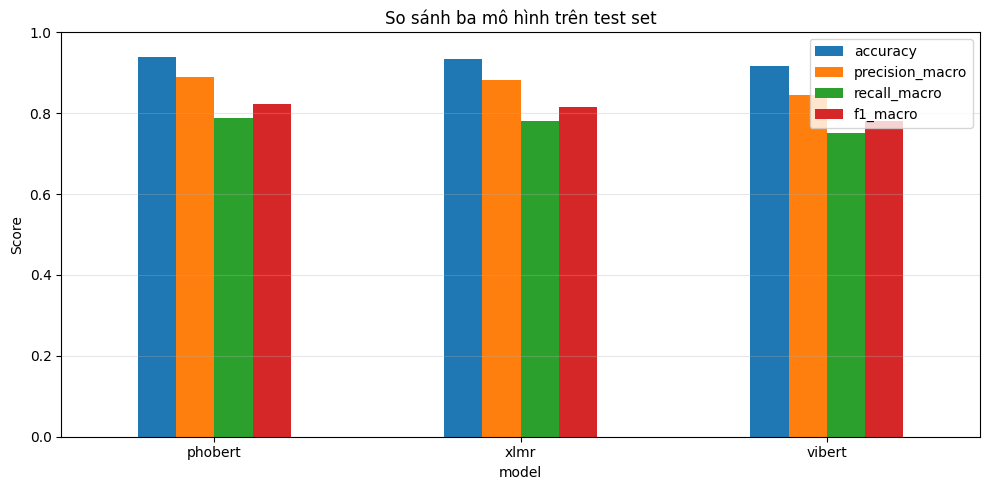

In [ ]:
results_df = pd.DataFrame(results).sort_values("f1_macro",ascending=False)
display(results_df)
results_df.to_csv("/content/uit_vsfc_plm_results.csv",index=False)

ax = results_df.set_index("model")[["accuracy","precision_macro","recall_macro","f1_macro"]].plot(
    kind="bar", figsize=(10,5), ylim=(0,1), rot=0
)
ax.set_ylabel("Score"); ax.set_title("So sánh ba mô hình trên test set")
ax.grid(axis="y",alpha=.3); plt.tight_layout(); plt.show()


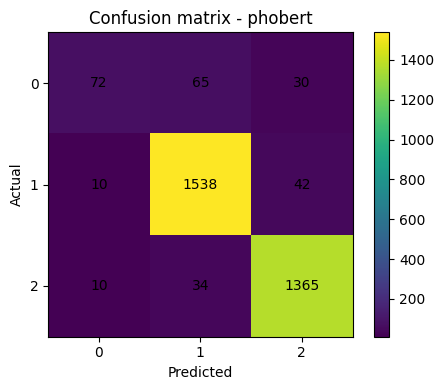

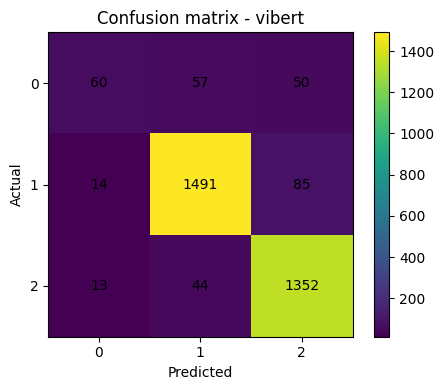

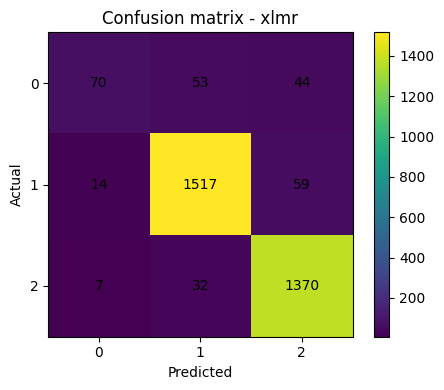

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
for model_key, y_pred in predictions.items():
    cm = confusion_matrix(test_df["label"], y_pred, labels=classes)
    fig, ax = plt.subplots(figsize=(5,4))
    im=ax.imshow(cm)
    ax.set_title(f"Confusion matrix - {model_key}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_xticks(range(len(classes)), classes)
    ax.set_yticks(range(len(classes)), classes)
    for i in range(len(classes)):
        for j in range(len(classes)): ax.text(j,i,str(cm[i,j]),ha="center",va="center")
    fig.colorbar(im); plt.tight_layout(); plt.show()

from google.colab import files
files.download("/content/uit_vsfc_plm_results.csv")


## 8. Hướng dẫn viết nhận xét trong báo cáo

- Dùng Macro-F1 làm chỉ số chính vì nó tính trung bình F1 trên từng lớp, tránh lớp đông chi phối.
- So sánh Accuracy, Precision, Recall, Macro-F1 và thời gian huấn luyện.
- Dùng confusion matrix để xem lớp nào bị nhầm nhiều.
- Nêu rõ phiên bản checkpoint, cách tiền xử lý PhoBERT, seed, split, epoch, batch size, learning rate và GPU.
- Chỉ kết luận dựa trên số liệu thực tế. Một seed chỉ là thực nghiệm ban đầu; nếu có thời gian, lặp 3 seed và báo cáo trung bình ± độ lệch chuẩn.
- Nếu dùng split chính thức của UIT-VSFC, không trộn rồi chia lại; điều đó giúp kết quả so sánh được với các nghiên cứu khác.
